# Customer Segmentaion using PCA and K-Means:

In this notebook we are going to apply unsupervised machine learning techniques to identify customer segments based on demographic and purchasing behavior.

The data cleaning and EDA parts were completed in the previous stages of the project respectively in  `data_cleaning.ipynb`and  `customer_eda.ipynb`.Based on these results, we selected the features useful for clustering.

The analysis consists mainly of three steps:

1. Standarize the selected features using StandardScaler.
2. Apply Principal Component Analysis (PCA) to examine the structure and reduce the dimensionality of the data.
3. Apply K-Means clustering and determine an appropriate number of customer segments.

The resulting cluster labels will later be used to interept the identified customer segments.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Load the Cleaned Data:
we are using the cleaned customer dataset as the input for the clustering analysis.


In [ ]:
df=pd.read_csv("../marketing_campaign_cleaned.csv")
df.head()



In [ ]:
df.shape

In [ ]:
df.info()

# 2. Features Selection:
Based on the data cleaning and exploratory data analysis, six features :Income, Age, Children, Recency, TotalSpending, and TotalPurchases were selected for clustering to address the research question: “What distinct customer segments can be identified based on demographic and purchasing behaviour, and which characteristics differentiate these segments?”.

These features represent broad demographic and purchasing characteristics
while limiting redundancy between variables. More detailed variables, such as
product-category spending, purchase channels, campaign responses, education,
and marital status, are excluded from the clustering process and will instead
be used later to characterize and interpret the resulting customer segments.

In [ ]:
features=["Income"
    ,"Age","Children",
    "Recency","TotalSpending",
    "TotalPurchases"
          
    
]
selected=df[features]
selected.head()


The selected features are summarized to get a better idea of their values and ranges before scaling.

In [ ]:
selected.describe()

# 3. Features scaling:
As we have seen , the features are measured on different numerical scales , since PCA and K-Means are sensitive to differences to features magnitude, a standardization of the variables is necessary before applying those methods.

For this , we are going to use StandardScaler that transforms each feature to have approximately zero mean and unit variance,which allows the selected variables to contribute on a comparable scale.

In [ ]:
scaler=StandardScaler()
selected_scaled=scaler.fit_transform(selected)
selected_scaled_df=pd.DataFrame(selected_scaled,columns=features)
selected_scaled_df.head()


# 4. Principal Component Analysis (PCA):

In this step we are going to apply PCA to the standardized features to check whether the dimensionality of the customer data can be reduced while
retaining most of its variation.

In [ ]:
pca=PCA()
selected_pca=pca.fit_transform(selected_scaled)
pca.explained_variance_ratio_


# 5. Variance explanation:
Now we are going to calculate the cumulative Variance , and then we will plot it to answer the question "How many principal components do we need to retain most of the information?".

In [ ]:
cum_variance=np.cumsum(pca.explained_variance_ratio_)
cum_variance

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(range(1,len(cum_variance)+1),
         cum_variance,
         marker="x")
plt.xlabel("Number of Cumulative Variance")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Varince by PCA")
plt.grid(True)
plt.show()

The cumulative explained variance shows that the first three principal components retain about 82.7% of the total variance, while four components retain about 93.2%. This suggests that most of the information in the six original features can be represented using three to four principal components.

# 7. PCA transformation:


The first three principal components retain approximately 82.7% of the total variance. Therefore, we decided to choose these 3 components to create a reduced representation of the data for the clustering analysis.

In [ ]:
pca_3=PCA(n_components=3)
selected_3=pca_3.fit_transform(selected_scaled)
selected_3.shape

for easier and clearer inspectation:


In [ ]:
selected_3_df=pd.DataFrame(selected_3,columns=["PC1","PC2","PC3"])
selected_3_df.head()

# 8. Choosing number of Clusters:
Before applying the final K-means model , we test different K values.Using the Elbow and Silouhette methods will help us identify the appropriate number of customer segments.


In [ ]:
k_values=range(2,16)
inertias=[]
silhouette_scores=[]
for k in k_values:
    kmeans=KMeans(n_clusters=k,random_state=42,n_init=15)
    clusters=kmeans.fit_predict(selected_3)
    inertias.append(kmeans.inertia_)    
    silhouette_scores.append(silhouette_score(selected_3,clusters))
print(len(k_values))
print(len(inertias))


# 8.1: Elbow plot:

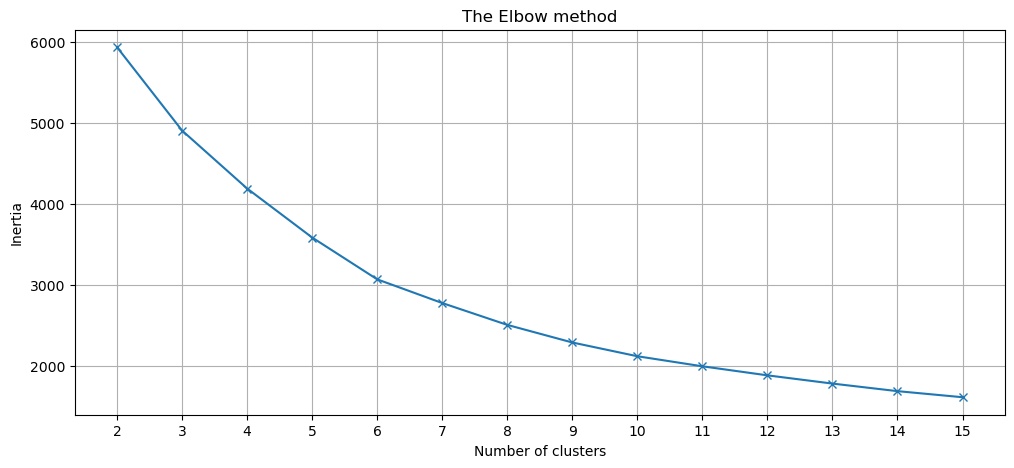

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(k_values,inertias,marker="x")
plt.xlabel("Number of clusters : k")
plt.ylabel("Inertia")
plt.title("The Elbow method")
plt.xticks(k_values)
plt.grid(True)
plt.show()

The elbow plot shows a noticeable change in slope around K = 6. After this point, the decrease in inertia becomes more gradual, suggesting that six clusters may provide a reasonable balance between cluster compactness and model complexity.

# 8.2: Silhouette plot:


In [ ]:
plt.figure(figsize=(12,5))
plt.plot(k_values,silhouette_scores,marker="x")
plt.xlabel("Clusters number : K")
plt.ylabel("Silhouette scores")
plt.title("Silhouette score for different K")
plt.xticks(k_values)
plt.grid(True)
plt.show()

The Silhouette score plot shows that K = 2 achieves the highest silhouette score of approximately 0.40, indicating the strongest cluster separation among the tested values.

# 9 . Comparison with 4 Principal Components :
The first three principal components retain approximately 82.7% of the total variance, while four components retain approximately 93.2%. To check whether the additional component affects the clustering results, K-Means is also applied using four principal components. The results are then compared with the three-component solution.

In [33]:
pca_4=PCA(n_components=4)
selected_4=pca_4.fit_transform(selected_scaled)
selected_4.shape

selected_4_df=pd.DataFrame(selected_4,columns=["PCA1","PCA2","PCA3","PCA4"])
selected_4_df.head()



,PCA1,PCA2,PCA3,PCA4
0,2.343741,0.342446,0.193135,-0.918640
1,-1.637564,1.589507,-0.776911,0.025265
2,1.655054,-0.377786,-0.773523,-0.608897
3,-1.799963,-1.371045,-0.458675,0.075146
4,-0.049545,-0.388005,1.714175,0.596806


In [ ]:
k_values in range(2,16)
inertias_4=[]
silhouette_scores_4=[]
for k in k_values:
    k_means=KMeans(n_clusters=k,n_init=15,random_state=42)
    clusters_4=k_means.fit_predict(selected_4)
    inertias_4.append(k_means.inertia_)
    silhouette_scores_4.append(silhouette_score(selected_4,clusters_4))

c:\Users\emili\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
c:\Users\emili\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
c:\Users\emili\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
c:\Users\emili\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

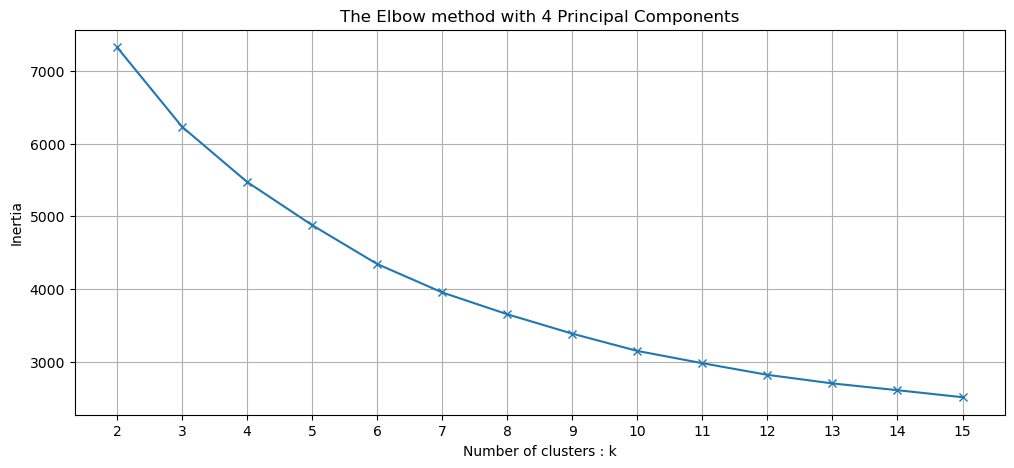

In [40]:
plt.figure(figsize=(12,5))
plt.plot(k_values,inertias_4,marker="x")
plt.xlabel("Number of clusters : k")
plt.ylabel("Inertia")
plt.title("The Elbow method with 4 Principal Components")
plt.xticks(k_values)
plt.grid(True)
plt.show()

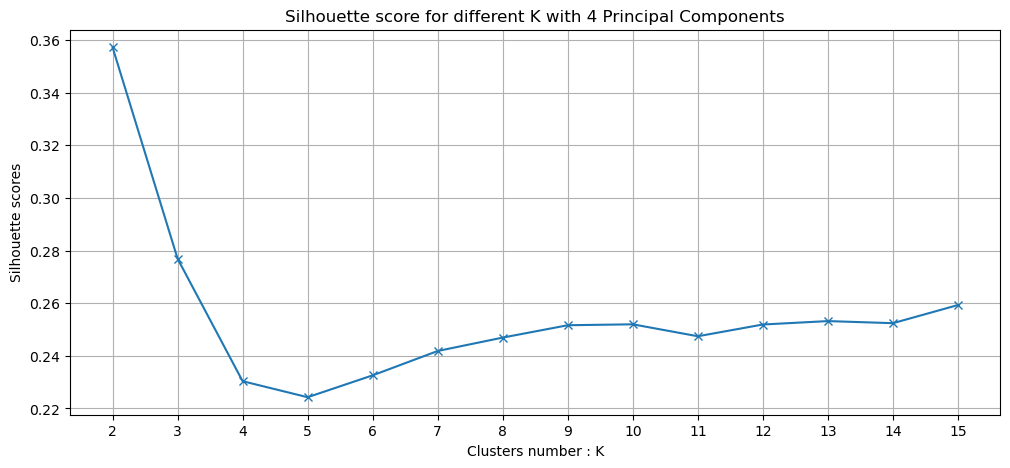

In [41]:
plt.figure(figsize=(12,5))
plt.plot(k_values,silhouette_scores_4,marker="x")
plt.xlabel("Clusters number : K")
plt.ylabel("Silhouette scores")
plt.title("Silhouette score for different K with 4 Principal Components")
plt.xticks(k_values)
plt.grid(True)
plt.show()

The first four principal components retain approximately 93.2% of the total variance, compared with 82.7% for three components. However, the clustering results using four components did not improve the Silhouette Scores and did not produce a clearer Elbow point. Therefore, three principal components were retained, as they provide a greater reduction in dimensionality while maintaining comparable or better clustering performance.

# 9 . Choosing the final number of clusters:
The Elbow Method suggests that the decrease in inertia starts to become smaller around k = 6. However, the Silhouette Score is highest for k = 2, indicating that two clusters provide the clearest separation.

Since the two methods suggest different solutions, both k = 2 and k = 6 will be examined before selecting the final clustering model. The final choice will also consider the size and interpretability of the resulting customer segments.

In [42]:
for k in [2,6]:
    model=KMeans(n_clusters=k,random_state=42,n_init=15)
    clusters=model.fit_predict(selected_3)
    temp=selected.copy()
    temp["Cluster"] = clusters
    print(f"\n--- k = {k} ---")
    print(temp.groupby("Cluster").mean().round(2))

c:\Users\emili\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(



--- k = 2 ---
           Income    Age  Children  Recency  TotalSpending  TotalPurchases
Cluster                                                                   
0        70802.06  47.55      0.55    49.29        1175.79           19.31
1        36942.38  43.12      1.27    48.80         154.20            7.19


c:\Users\emili\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(



--- k = 6 ---
           Income    Age  Children  Recency  TotalSpending  TotalPurchases
Cluster                                                                   
0        69348.88  53.27      0.68    73.57        1133.98           19.18
1        33115.20  38.10      1.06    23.16         121.97            6.41
2        42397.92  54.45      1.84    55.58         169.99            7.72
3        77337.71  34.77      0.08    47.72        1481.02           20.12
4        34347.14  37.01      0.98    75.58         148.11            7.01
5        65348.65  51.67      0.81    22.03         902.08           18.04


The Silhouette Score was highest for k = 2, indicating the strongest overall cluster separation. However, the Elbow Method suggested that additional structure could be captured with approximately six clusters. The two-cluster solution mainly separated customers into broad high- and low-value groups, while the six-cluster solution revealed more detailed differences in income, age, household composition, recency, spending, and purchasing frequency.
 
Therefore, k = 6 was selected as a more informative solution for customer segmentation.

In [43]:
final_k = 6

model = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

cluster_labels = model.fit_predict(selected_3)

pd.Series(cluster_labels).value_counts().sort_index()

c:\Users\emili\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


0    270
1    369
2    371
3    381
4    382
5    439
Name: count, dtype: int64

All clusters sizes add up to 2212 without creating any tiny, meaningless clusters.

# 10. Adding clusters to the data:


In [ ]:
df_clustered=df.copy()
df_clustered["Cluster"]=cluster_labels
df_clustered[
    ["Income", "Age", "Children", "Recency",
     "TotalSpending", "TotalPurchases", "Cluster"]
].head()

# 11 . Visualizing the Clusters with PCA:
After selecting the number of clusters, the resulting customer segments are visualized using the principal components obtained from PCA. Each point represents a customer, while the different colors represent the clusters assigned by the K-Means algorithm.

This visualization helps to examine how well the identified customer segments are separated in the PCA space.

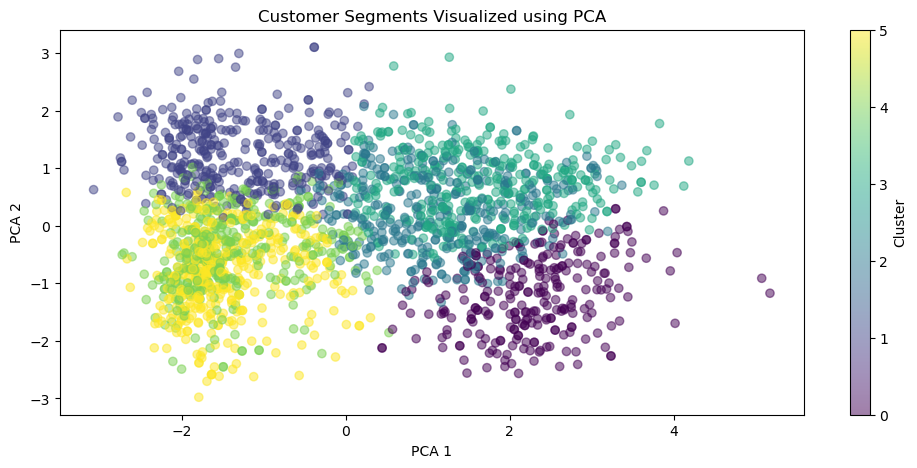

In [28]:
plt.figure(figsize=(12,5))
scatter=plt.scatter(selected_3[:,0],selected_3[:,1],c=cluster_labels,alpha=0.5)
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Customer Segments Visualized using PCA")
plt.colorbar(scatter, label="Cluster")
plt.show()

The customer segments are visualized using the first two principal components, PCA 1 and PCA 2. Each point represents a customer, while the different colors represent the clusters identified by K-Means.

Since K-Means clustering was performed using three principal components, this figure represents only a two-dimensional projection of the clustering results. Therefore, some customers that appear close or overlapping in this visualization may still be separated along the third principal component (PCA 3).

# 12 . Saving the Clustering results:


The final clustering results are saved in a new CSV file, including the cluster assigned to each customer. This dataset can then be used for further analysis and interpretation of the customer segments.

In [ ]:
df_clustered.to_csv(  "../marketing_campaign_clustered.csv",
    index=False
)